DATASET INFORMATION
--------------------------------------------------
Shape: (58478, 22)

First five rows:
   Diabetes_012  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0           0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1           0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2           0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3           0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4           0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  S

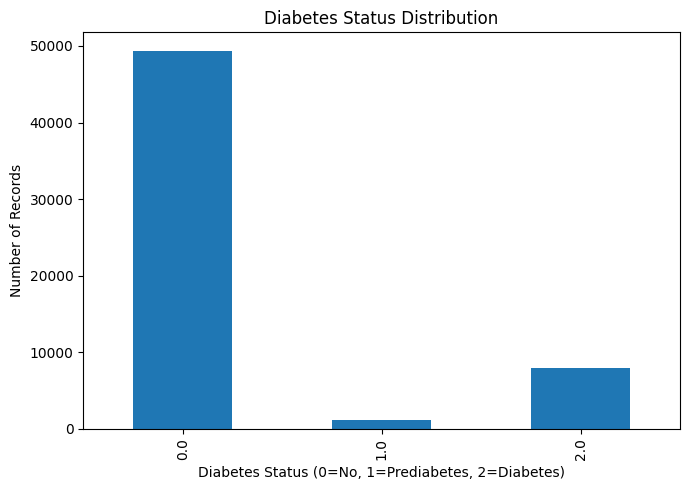


Training records: 46782
Testing records: 11696

Logistic Regression
Accuracy: 0.642
Balanced Accuracy: 0.5085
Macro F1: 0.4245
Weighted F1: 0.7167

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.95      0.66      0.78      9864
 Prediabetes       0.03      0.26      0.05       236
    Diabetes       0.35      0.61      0.44      1596

    accuracy                           0.64     11696
   macro avg       0.44      0.51      0.42     11696
weighted avg       0.85      0.64      0.72     11696



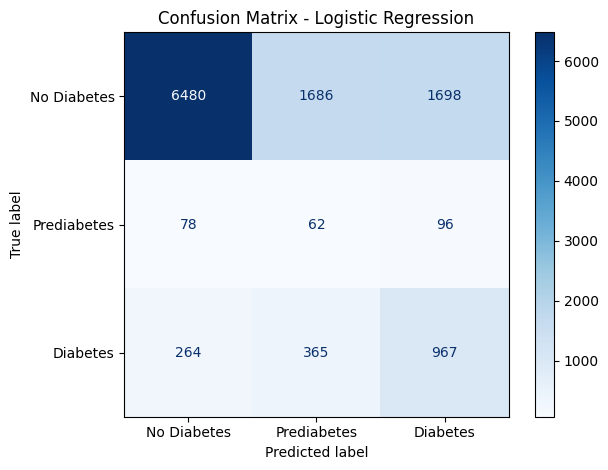


Random Forest
Accuracy: 0.8266
Balanced Accuracy: 0.4382
Macro F1: 0.4375
Weighted F1: 0.8163

Classification Report:
              precision    recall  f1-score   support

 No Diabetes       0.89      0.92      0.90      9864
 Prediabetes       0.00      0.00      0.00       236
    Diabetes       0.42      0.40      0.41      1596

    accuracy                           0.83     11696
   macro avg       0.44      0.44      0.44     11696
weighted avg       0.81      0.83      0.82     11696



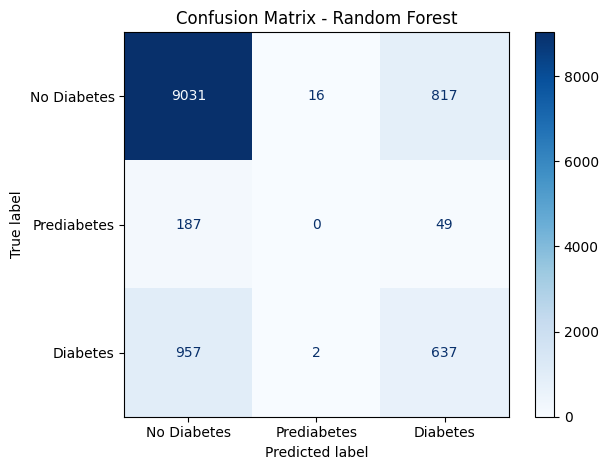


Top 15 Important Features:
BMI             0.168680
Age             0.132985
Income          0.094397
GenHlth         0.080579
PhysHlth        0.074942
Education       0.065952
MentHlth        0.064805
HighBP          0.044836
Smoker          0.035514
HighChol        0.034602
Sex             0.034126
Fruits          0.032876
PhysActivity    0.027202
Veggies         0.025154
DiffWalk        0.020660
dtype: float64


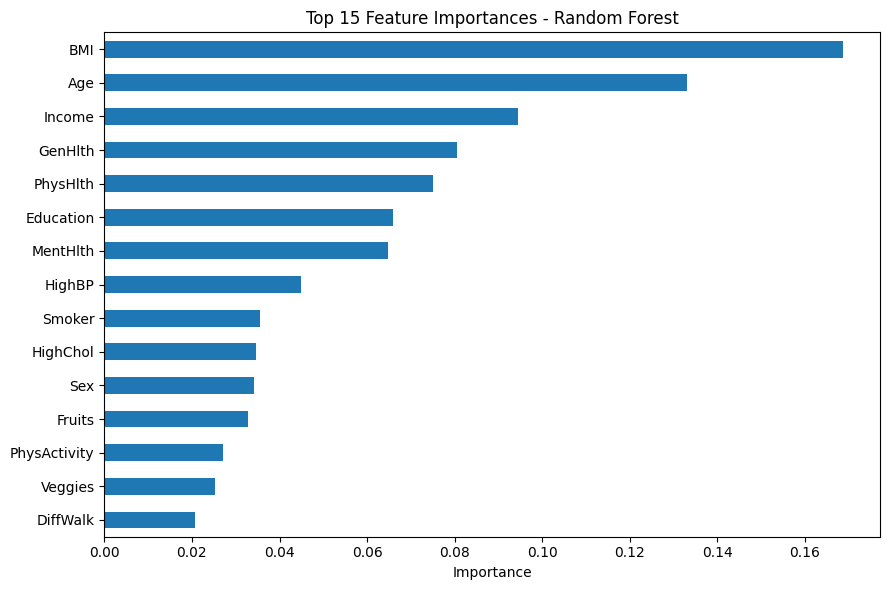


MODEL COMPARISON
              Model  Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Logistic Regression  0.642014           0.508512  0.424457     0.716677
      Random Forest  0.826607           0.438225  0.437481     0.816258

Project 1 completed successfully!
Results saved in the diabetes_outputs folder.


In [ ]:
# ============================================
# PROJECT 1: DIABETES STATUS CLASSIFICATION
# Algorithms: Logistic Regression, Random Forest
# Dataset: diabetes_012_health_indicators_BRFSS2015.csv
# ============================================

import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# 1. Load dataset
df = pd.read_csv("/content/diabetes_012_health_indicators_BRFSS2015.csv")

print("DATASET INFORMATION")
print("-" * 50)
print("Shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# 2. Explore target distribution
target = "Diabetes_012"

print("\nTarget distribution:")
print(df[target].value_counts().sort_index())

print("\nTarget distribution percentage:")
print((df[target].value_counts(normalize=True).sort_index() * 100).round(2))

df[target].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 5)
)
plt.title("Diabetes Status Distribution")
plt.xlabel("Diabetes Status (0=No, 1=Prediabetes, 2=Diabetes)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# 3. Prepare features and target
df = df.dropna(subset=[target])
df = df[df[target].isin([0, 1, 2])].copy()

X = df.drop(columns=[target])
y = df[target].astype(int)

# 4. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 5. Define models
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1500,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced_subsample",
            n_jobs=-1,
            min_samples_leaf=2
        ))
    ])
}

# 6. Train and evaluate models
os.makedirs("diabetes_outputs", exist_ok=True)
results = []

for name, model in models.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    balanced_acc = balanced_accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test, predictions, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_test, predictions, average="weighted", zero_division=0
    )

    print("Accuracy:", round(accuracy, 4))
    print("Balanced Accuracy:", round(balanced_acc, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Weighted F1:", round(weighted_f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1, 2],
        target_names=["No Diabetes", "Prediabetes", "Diabetes"],
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_test, predictions, labels=[0, 1, 2])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Diabetes", "Prediabetes", "Diabetes"]
    )

    display.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()

    filename = name.lower().replace(" ", "_")
    plt.savefig(
        f"diabetes_outputs/{filename}_confusion_matrix.png"
    )
    plt.show()
    plt.close()

    # Save trained model
    import joblib
    joblib.dump(model, f"diabetes_outputs/{filename}.joblib")

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_acc,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    })

    # Random Forest feature importance
    if name == "Random Forest":

        importances = model.named_steps["classifier"].feature_importances_

        feature_importance = pd.Series(
            importances,
            index=X.columns
        ).sort_values(ascending=False)

        print("\nTop 15 Important Features:")
        print(feature_importance.head(15))

        feature_importance.head(15).sort_values().plot(
            kind="barh", figsize=(9, 6)
        )
        plt.title("Top 15 Feature Importances - Random Forest")
        plt.xlabel("Importance")
        plt.tight_layout()
        plt.savefig("diabetes_outputs/feature_importance.png")
        plt.show()
        plt.close()

        feature_importance.to_csv(
            "diabetes_outputs/feature_importance.csv"
        )

# 7. Compare models
comparison = pd.DataFrame(results)

print("\nMODEL COMPARISON")
print(comparison.to_string(index=False))

comparison.to_csv(
    "diabetes_outputs/model_comparison.csv",
    index=False
)

print("\nProject 1 completed successfully!")
print("Results saved in the diabetes_outputs folder.")

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import joblib
import os

# Load dataset
df = pd.read_csv("/content/diabetes_012_health_indicators_BRFSS2015.csv")

target = "Diabetes_012"

X = df.drop(columns=[target])
y = df[target].astype(int)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

# Evaluate
predictions = model.predict(X_test)

print("\nModel Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

# Interactive prediction
print("\n===== DIABETES STATUS PREDICTION =====")
print("Enter the values for the following features.")
print("Use the dataset's original feature definitions and coding.\n")

feature_values = {}

for column in X.columns:
    while True:
        try:
            value = float(input(f"Enter {column}: "))
            feature_values[column] = value
            break
        except ValueError:
            print("Please enter a valid numeric value.")

input_data = pd.DataFrame([feature_values], columns=X.columns)

result = model.predict(input_data)[0]

labels = {
    0: "No Diabetes",
    1: "Prediabetes",
    2: "Diabetes"
}

print("\n===== PREDICTION RESULT =====")
print("Predicted Class:", result)
print("Predicted Status:", labels.get(result, "Unknown"))

print("\nNote: This is an educational ML prediction,")
print("not a medical diagnosis.")


Model Accuracy: 0.6457544938505203

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.66      0.78     42741
           1       0.03      0.33      0.06       926
           2       0.35      0.58      0.44      7069

    accuracy                           0.65     50736
   macro avg       0.45      0.52      0.43     50736
weighted avg       0.85      0.65      0.72     50736


===== DIABETES STATUS PREDICTION =====
Enter the values for the following features.
Use the dataset's original feature definitions and coding.

Enter HighBP: 1
Enter HighChol: 1
Enter CholCheck: 27
Enter BMI: 50
Enter Smoker: No
Please enter a valid numeric value.
Enter Smoker: 0
Enter Stroke: 0
Enter HeartDiseaseorAttack: 0
Enter PhysActivity: 1
Enter Fruits: 1
Enter Veggies: 1
Enter HvyAlcoholConsump: 0
Enter AnyHealthcare: 0
Enter NoDocbcCost: 0
Enter GenHlth: 1
Enter MentHlth: 1
Enter PhysHlth: 1
Enter DiffWalk: 1
Enter Sex: 1
Enter Age: 45
Enter E

In [ ]:
"""
Diabetes Status Classification using Logistic Regression, Random Forest, and XGBoost.

Dataset: diabetes_012_health_indicators_BRFSS2015.csv
Install: pip install pandas numpy scikit-learn matplotlib xgboost
Run:     python diabetes_classification_three_algorithms.py

Accuracy and other aggregate metrics are printed as percentages (e.g. 75.23%).
"""

from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay,
    confusion_matrix, f1_score, precision_score, recall_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

DATASET_PATH = Path("/content/diabetes_012_health_indicators_BRFSS2015.csv")
TARGET = "Diabetes_012"
RANDOM_STATE = 42
TEST_SIZE = 0.20
CLASS_NAMES = {0: "No Diabetes", 1: "Prediabetes", 2: "Diabetes"}


def load_dataset(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found: {path}\nPut the CSV in the same folder as this script "
            "or update DATASET_PATH."
        )
    df = pd.read_csv(path, low_memory=False)
    if TARGET not in df.columns:
        raise ValueError(f"Target column '{TARGET}' not found in dataset.")
    df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
    df = df.dropna(subset=[TARGET]).copy()
    df[TARGET] = df[TARGET].astype(int)
    unexpected = sorted(set(df[TARGET].unique()) - set(CLASS_NAMES))
    if unexpected:
        raise ValueError(f"Unexpected target labels: {unexpected}")
    return df


def build_models():
    models = {
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
            )),
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=300, class_weight="balanced",
                random_state=RANDOM_STATE, n_jobs=-1
            )),
        ]),
    }

    try:
        from xgboost import XGBClassifier
        models["XGBoost"] = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBClassifier(
                objective="multi:softprob",
                num_class=3,
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.9,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ])
    except ImportError:
        print(
            "\nWARNING: XGBoost package is not installed, so it will be skipped. "
            "Install it using: pip install xgboost\n"
        )
    return models


def main():
    df = load_dataset(DATASET_PATH)
    print("=" * 72)
    print("DIABETES STATUS CLASSIFICATION")
    print("=" * 72)
    print(f"Dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(f"Target column: {TARGET}")
    print("\nTarget class distribution:")
    for label, count in df[TARGET].value_counts().sort_index().items():
        print(
            f"  {label} - {CLASS_NAMES[int(label)]:14s}: "
            f"{count:,} ({count / len(df) * 100:.2f}%)"
        )

    X = df.drop(columns=[TARGET]).copy()
    y = df[TARGET].copy()
    # Ensure feature columns are numeric; unexpected text is treated as missing.
    for column in X.columns:
        X[column] = pd.to_numeric(X[column], errors="coerce")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
    )
    print(f"\nTraining rows: {len(X_train):,}")
    print(f"Testing rows:  {len(X_test):,}")
    print("\nTraining models...")

    models = build_models()
    results = []
    predictions = {}
    for name, model in models.items():
        print(f"  Training {name}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        predictions[name] = y_pred
        results.append({
            "Algorithm": name,
            "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
            "Macro Precision (%)": round(
                precision_score(y_test, y_pred, average="macro", zero_division=0) * 100, 2
            ),
            "Macro Recall (%)": round(
                recall_score(y_test, y_pred, average="macro", zero_division=0) * 100, 2
            ),
            "Macro F1 (%)": round(
                f1_score(y_test, y_pred, average="macro", zero_division=0) * 100, 2
            ),
        })

    results_df = pd.DataFrame(results).sort_values(
        "Macro F1 (%)", ascending=False
    ).reset_index(drop=True)
    print("\n" + "=" * 72)
    print("MODEL COMPARISON (metrics shown as percentages)")
    print("=" * 72)
    print(results_df.to_string(index=False, formatters={
        "Accuracy (%)": "{:.2f}%".format,
        "Macro Precision (%)": "{:.2f}%".format,
        "Macro Recall (%)": "{:.2f}%".format,
        "Macro F1 (%)": "{:.2f}%".format,
    }))
    results_df.to_csv("diabetes_model_comparison.csv", index=False)
    print("\nSaved: diabetes_model_comparison.csv")

    # Choose the best model using Macro F1, not accuracy alone, because classes are imbalanced.
    best_name = results_df.iloc[0]["Algorithm"]
    best_pred = predictions[best_name]
    print(f"\nBest model by Macro F1: {best_name}")
    print(f"Accuracy: {accuracy_score(y_test, best_pred) * 100:.2f}%")
    report = classification_report(
        y_test, best_pred, labels=[0, 1, 2],
        target_names=[CLASS_NAMES[i] for i in [0, 1, 2]],
        zero_division=0, digits=4
    )
    print("\nClassification report:")
    print(report)
    Path("diabetes_classification_report.txt").write_text(report, encoding="utf-8")
    print("Saved: diabetes_classification_report.txt")

    cm = confusion_matrix(y_test, best_pred, labels=[0, 1, 2])
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[CLASS_NAMES[i] for i in [0, 1, 2]]
    ).plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"Confusion Matrix - {best_name}")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig("diabetes_confusion_matrix.png", dpi=180, bbox_inches="tight")
    plt.close(fig)
    print("Saved: diabetes_confusion_matrix.png")

    answer = input("\nTry a new prediction by entering feature values? (y/n): ").strip().lower()
    if answer == "y":
        print("\nEnter one numeric value for each feature in this exact order:")
        print(", ".join(X.columns))
        values = []
        for column in X.columns:
            while True:
                try:
                    values.append(float(input(f"{column}: ").strip()))
                    break
                except ValueError:
                    print("Please enter a numeric value.")
        new_record = pd.DataFrame([values], columns=X.columns)
        model = build_models()[best_name]
        model.fit(X_train, y_train)
        prediction = int(model.predict(new_record)[0])
        print(f"Predicted class: {prediction} - {CLASS_NAMES[prediction]}")
        if hasattr(model, "predict_proba"):
            try:
                scores = model.predict_proba(new_record)[0]
                print("Model scores (not medical probabilities):")
                for class_id, score in zip(model.classes_, scores):
                    print(f"  {CLASS_NAMES[int(class_id)]}: {score * 100:.2f}%")
            except Exception:
                pass
        print("Educational demonstration only; this is not a medical diagnosis.")

    print("\nDone.")


if __name__ == "__main__":
    main()


DIABETES STATUS CLASSIFICATION
Dataset: 253,680 rows x 22 columns
Target column: Diabetes_012

Target class distribution:
  0 - No Diabetes   : 213,703 (84.24%)
  1 - Prediabetes   : 4,631 (1.83%)
  2 - Diabetes      : 35,346 (13.93%)

Training rows: 202,944
Testing rows:  50,736

Training models...
  Training Logistic Regression...
  Training Random Forest...
  Training XGBoost...

MODEL COMPARISON (metrics shown as percentages)
          Algorithm Accuracy (%) Macro Precision (%) Macro Recall (%) Macro F1 (%)
Logistic Regression       64.58%              44.56%           52.42%       42.69%
            XGBoost       85.02%              47.68%           38.76%       39.85%
      Random Forest       83.92%              44.49%           37.59%       38.27%

Saved: diabetes_model_comparison.csv

Best model by Macro F1: Logistic Regression
Accuracy: 64.58%

Classification report:
              precision    recall  f1-score   support

 No Diabetes     0.9510    0.6630    0.7813     42741
 

In [2]:
#!/usr/bin/env python3
"""
Diabetes Status Classification (BRFSS 2015) -- B.Tech ML Lab project
====================================================================
Run:   python diabetes_classification.py --data diabetes_012_health_indicators_BRFSS2015.csv
Output: everything is saved inside the folder given by --outdir (default: results/)

IMPORTANT: this is an educational / exploratory model. It predicts a survey
self-report label from health indicators. It is NOT a medical diagnosis tool
and has NOT been clinically validated.

Workflow
  1. Load + inspect the data (no rows are removed or changed)
  2. Stratified 80:20 train/test split (random_state=42) BEFORE any fitting
  3. Train 5 models. All scaling lives inside sklearn Pipelines, so it is
     fitted on training data only (no leakage). Class imbalance is handled
     with class weights (training data only) -- no SMOTE / oversampling.
  4. Evaluate every model on the same held-out test set
  5. Select the best model by MACRO F1 (not accuracy)
  6. Save tables, charts, the model, and slide/summary text
  7. Demonstrate a reusable prediction function
"""

import argparse
import time
import warnings
from pathlib import Path

import joblib
import matplotlib

matplotlib.use("Agg")  # draw to files; works without a display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             precision_recall_fscore_support, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils.validation import check_is_fitted
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

# ----------------------------------------------------------------------------
# Settings
# ----------------------------------------------------------------------------
RANDOM_STATE = 42
TARGET = "Diabetes_012"
CLASSES = [0, 1, 2]
# NOTE: The CSV itself contains NO data dictionary. These meanings come from the
# published BRFSS 2015 / Kaggle dataset documentation, not from the file.
LABELS = {0: "No Diabetes", 1: "Prediabetes", 2: "Diabetes"}
CLASS_NAMES = [LABELS[c] for c in CLASSES]
# The RBF-kernel SVM scales roughly O(n^2)-O(n^3): infeasible on ~200k rows on
# a laptop. It is trained on a stratified SUBSAMPLE of the TRAINING set only;
# it is still evaluated on the full, same test set as the other models.
SVM_TRAIN_SAMPLE = 10000
PERM_IMPORTANCE_SAMPLE = 15000


def banner(text):
    print("\n" + "=" * 78 + f"\n{text}\n" + "=" * 78)


def pct(x):
    return round(100 * float(x), 2)


# ----------------------------------------------------------------------------
# 1. Load and inspect
# ----------------------------------------------------------------------------
def load_and_inspect(path, outdir):
    banner("1. DATASET INSPECTION")
    df = pd.read_csv("/content/diabetes_012_health_indicators_BRFSS2015.csv")
    print(f"Rows x columns : {df.shape[0]:,} x {df.shape[1]}")
    print("\nColumn names and dtypes:")
    print(df.dtypes.to_string())

    if TARGET not in df.columns:
        raise ValueError(f"Expected target column '{TARGET}' not found. Columns: {list(df.columns)}")
    values = sorted(df[TARGET].dropna().unique())
    print(f"\nTarget column '{TARGET}' unique values: {values}")
    if set(values) != set(CLASSES):
        raise ValueError(f"Target values {values} differ from expected {CLASSES}; "
                         "check the dataset before continuing.")

    missing = df.isna().sum()
    print(f"\nMissing values (total {int(missing.sum())}):")
    print(missing[missing > 0].to_string() if missing.sum() else "  none in any column")

    n_dup = int(df.duplicated().sum())
    print(f"\nExact duplicate rows: {n_dup:,} ({100 * n_dup / len(df):.2f}%)  -> KEPT (see notes below)")

    features = [c for c in df.columns if c != TARGET]
    grp = df.groupby(features)[TARGET].nunique()
    n_conflict = int((grp > 1).sum())
    print(f"Identical feature vectors that carry DIFFERENT labels: {n_conflict:,} groups "
          "(label noise inherent to the data)")

    counts = df[TARGET].value_counts().sort_index()
    dist = pd.DataFrame({"class": [LABELS[int(i)] for i in counts.index],
                         "count": counts.values,
                         "percent": (100 * counts / len(df)).round(3).values}, index=counts.index)
    print("\nTarget distribution:")
    print(dist.to_string())
    ratio = counts.max() / counts.min()
    print(f"Imbalance ratio (largest/smallest class): {ratio:.1f} : 1")

    binary = [c for c in features if df[c].nunique() == 2]
    numeric = [c for c in features if df[c].nunique() > 2]
    print(f"\nBinary (0/1) features ({len(binary)}): {binary}")
    print(f"Ordinal / numeric features ({len(numeric)}): {numeric}")
    print("(All columns are stored as float64 but most are really binary or ordinal codes.)")
    print(f"\nBMI min/max: {df['BMI'].min():.0f}/{df['BMI'].max():.0f}; rows with BMI > 60: "
          f"{int((df['BMI'] > 60).sum()):,} (kept: may be real or recording errors)")

    # Chart 1: target distribution
    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(dist["class"], dist["count"], color=["#4C72B0", "#DD8452", "#C44E52"])
    for b, c, p in zip(bars, dist["count"], dist["percent"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{c:,}\n({p:.2f}%)",
                ha="center", va="bottom", fontsize=9)
    ax.set_title("Target-Class Distribution (Diabetes_012, full dataset)")
    ax.set_xlabel("Diabetes status")
    ax.set_ylabel("Number of respondents")
    ax.set_ylim(0, dist["count"].max() * 1.18)
    fig.tight_layout()
    fig.savefig(outdir / "target_distribution.png", dpi=150)
    plt.close(fig)

    info = {"n_rows": len(df), "n_cols": df.shape[1], "n_dup": n_dup, "n_conflict": n_conflict,
            "dist": dist, "imbalance_ratio": ratio}
    return df, features, info


# ----------------------------------------------------------------------------
# 2-3. Split and models
# ----------------------------------------------------------------------------
def build_models():
    """Each model is a Pipeline so scaling is fitted on training data only."""
    return {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                       random_state=RANDOM_STATE))]),  # lbfgs -> multinomial
        "Decision Tree": Pipeline([
            ("scaler", "passthrough"),  # trees do not need scaling
            ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                           class_weight="balanced", random_state=RANDOM_STATE))]),
        "Random Forest": Pipeline([
            ("scaler", "passthrough"),
            ("clf", RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=10,
                                           class_weight="balanced_subsample", n_jobs=-1,
                                           random_state=RANDOM_STATE))]),
        "SVM": Pipeline([
            ("scaler", StandardScaler()),  # SVMs REQUIRE scaled features
            ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced",
                        decision_function_shape="ovr", random_state=RANDOM_STATE))]),
        "XGBoost": Pipeline([
            ("scaler", "passthrough"),
            ("clf", XGBClassifier(objective="multi:softprob", num_class=len(CLASSES),
                                  n_estimators=300, max_depth=6, learning_rate=0.1,
                                  subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                                  eval_metric="mlogloss", n_jobs=-1,
                                  random_state=RANDOM_STATE))]),
    }


def get_scores(model, X):
    """Class scores for ROC: probabilities if available, else decision scores."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)
    return model.decision_function(X)


def macro_ovr_auc(y_true_bin, scores):
    """One-vs-rest ROC-AUC: one binary AUC per class, then the unweighted mean.
    (Done manually because roc_auc_score's built-in multiclass mode only accepts
    probabilities, while the SVM provides decision scores.)"""
    per_class = [roc_auc_score(y_true_bin[:, k], scores[:, k]) for k in range(len(CLASSES))]
    return float(np.mean(per_class)), per_class


# ----------------------------------------------------------------------------
# 9. Prediction function (works from a saved bundle, no retraining)
# ----------------------------------------------------------------------------
def predict_diabetes_status(new_data, model_path="results/best_model.joblib"):
    """
    Predict diabetes status from health indicators.

    new_data : dict (one person) or DataFrame (several people) with EXACTLY the
               training feature columns.
    Returns  : list of dicts with predicted_class, predicted_label and
               probabilities (None if the chosen model has no predict_proba).
    Probabilities are model scores, NOT clinically calibrated risks.
    """
    bundle = joblib.load(model_path) if isinstance(model_path, (str, Path)) else model_path
    feats = bundle["feature_names"]

    if isinstance(new_data, dict):
        df = pd.DataFrame([new_data])
    elif isinstance(new_data, pd.DataFrame):
        df = new_data.copy()
    else:
        raise TypeError("new_data must be a dict (one record) or a pandas DataFrame.")

    missing = [c for c in feats if c not in df.columns]
    extra = [c for c in df.columns if c not in feats]
    if missing or extra:
        raise ValueError(f"Input columns do not match training features. Missing: {missing}. "
                         f"Unexpected: {extra}. Expected: {feats}")
    df = df[feats]
    try:
        df = df.astype(float)
    except (ValueError, TypeError) as exc:
        raise ValueError(f"All inputs must be numeric. Details: {exc}")
    if df.isna().any().any():
        raise ValueError(f"Input contains missing values in: {df.columns[df.isna().any()].tolist()}")
    lo, hi = bundle["train_min"], bundle["train_max"]
    bad = [c for c in feats if ((df[c] < lo[c]) | (df[c] > hi[c])).any()]
    if bad:
        raise ValueError("Values outside the range seen in training data for: "
                         + ", ".join(f"{c} (allowed {lo[c]:g}-{hi[c]:g})" for c in bad))

    pipe = bundle["pipeline"]
    preds = pipe.predict(df)
    proba = pipe.predict_proba(df) if hasattr(pipe, "predict_proba") else None
    out = []
    for i, p in enumerate(preds):
        p = int(p)
        out.append({"predicted_class": p,
                    "predicted_label": bundle["labels"][p],
                    "probabilities": None if proba is None else
                    {bundle["labels"][int(c)]: float(proba[i, j])
                     for j, c in enumerate(pipe.classes_)}})
    return out


# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="diabetes_012_health_indicators_BRFSS2015.csv")
    ap.add_argument("--outdir", default="results")
    args = ap.parse_args()
    outdir = Path(args.outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    df, features, info = load_and_inspect(args.data, outdir)
    X = df[features]
    y = df[TARGET].astype(int)

    # ---- split BEFORE anything is fitted --------------------------------
    banner("2. TRAIN / TEST SPLIT (80:20, stratified, random_state=42)")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
    print("Train class %:", (100 * y_train.value_counts(normalize=True).sort_index()).round(2).to_dict())
    print("Test  class %:", (100 * y_test.value_counts(normalize=True).sort_index()).round(2).to_dict())

    # Duplicate leakage check: do test feature-vectors also appear in training?
    h_train = set(pd.util.hash_pandas_object(X_train, index=False))
    in_train = pd.util.hash_pandas_object(X_test, index=False).isin(h_train).to_numpy()
    print(f"Test rows whose exact feature vector also appears in the training set: "
          f"{int(in_train.sum()):,} ({100 * in_train.mean():.2f}%) -> may slightly inflate scores")

    # ---- training ----------------------------------------------------------
    banner("3. TRAINING (class imbalance handled by class weights, training data only)")
    models = build_models()
    sw_train = compute_sample_weight("balanced", y_train)  # for XGBoost
    y_bin = label_binarize(y_test, classes=CLASSES)
    results = {}
    for name, model in models.items():
        t0 = time.time()
        if name == "SVM":
            Xs, _, ys, _ = train_test_split(X_train, y_train, train_size=SVM_TRAIN_SAMPLE,
                                            stratify=y_train, random_state=RANDOM_STATE)
            print(f"[SVM] training on a stratified subsample of {len(Xs):,} training rows")
            model.fit(Xs, ys)
        elif name == "XGBoost":
            model.fit(X_train, y_train, clf__sample_weight=sw_train)
        else:
            model.fit(X_train, y_train)
        fit_s = time.time() - t0

        t1 = time.time()
        y_pred = model.predict(X_test)
        scores = get_scores(model, X_test)
        pred_s = time.time() - t1
        auc, auc_each = macro_ovr_auc(y_bin, scores)
        p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
        results[name] = dict(
            y_pred=y_pred, scores=scores, auc=auc, auc_each=auc_each, fit_s=fit_s, pred_s=pred_s,
            acc=accuracy_score(y_test, y_pred), mp=p, mr=r, mf1=f,
            wf1=f1_score(y_test, y_pred, average="weighted", zero_division=0))
        print(f"{name:20s} fit {fit_s:7.1f}s | predict {pred_s:6.1f}s | acc {pct(results[name]['acc']):.2f}% "
              f"| macro-F1 {pct(f):.2f}% | macro-AUC {auc:.4f}")

    # ---- evaluation ----------------------------------------------------------
    banner("4. EVALUATION ON THE HELD-OUT TEST SET")
    rows, rep_rows = [], []
    for name, r in results.items():
        rows.append({"Model": name, "Accuracy (%)": pct(r["acc"]),
                     "Macro Precision (%)": pct(r["mp"]), "Macro Recall (%)": pct(r["mr"]),
                     "Macro F1 (%)": pct(r["mf1"]), "Weighted F1 (%)": pct(r["wf1"]),
                     "Macro ROC-AUC (OvR)": round(r["auc"], 4),
                     "Train time (s)": round(r["fit_s"], 1), "Predict time (s)": round(r["pred_s"], 1)})
        rep = classification_report(y_test, r["y_pred"], target_names=CLASS_NAMES,
                                    output_dict=True, zero_division=0)
        for cls, d in rep.items():
            if cls == "accuracy":
                continue
            rep_rows.append({"Model": name, "Class": cls, "Precision": d["precision"],
                             "Recall": d["recall"], "F1-score": d["f1-score"], "Support": int(d["support"])})
        print(f"\n--- {name} ---")
        print(classification_report(y_test, r["y_pred"], target_names=CLASS_NAMES,
                                    digits=4, zero_division=0))
    comp = pd.DataFrame(rows)
    comp.to_csv(outdir / "model_comparison.csv", index=False)
    rep_df = pd.DataFrame(rep_rows)
    rep_df.to_csv(outdir / "classification_report.csv", index=False)
    print("\nMODEL COMPARISON (test set):")
    print(comp.to_string(index=False))

    # ---- model selection (primary metric: macro F1) -------------------------
    banner("5. MODEL SELECTION (primary metric: macro F1)")
    best = comp.loc[comp["Macro F1 (%)"].idxmax(), "Model"]
    top2 = comp.sort_values("Macro F1 (%)", ascending=False).head(2)
    print(f"Selected model: {best}")
    print(f"Top-2 macro-F1 gap: {top2['Macro F1 (%)'].iloc[0] - top2['Macro F1 (%)'].iloc[1]:.2f} points")
    best_res = results[best]

    # ---- charts ----------------------------------------------------------------
    colors = sns.color_palette("deep", len(comp))
    for col, fname, title in [("Accuracy (%)", "model_accuracy_comparison.png", "Test Accuracy by Model"),
                              ("Macro F1 (%)", "model_f1_comparison.png", "Test Macro F1-Score by Model")]:
        fig, ax = plt.subplots(figsize=(8, 4.8))
        bars = ax.bar(comp["Model"], comp[col], color=colors)
        for b, v in zip(bars, comp[col]):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.2f}%", ha="center", fontsize=9)
        ax.set_title(title + " (held-out test set)")
        ax.set_xlabel("Model")
        ax.set_ylabel(col)
        ax.set_ylim(0, 105)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        fig.savefig(outdir / fname, dpi=150)
        plt.close(fig)

    cm = confusion_matrix(y_test, best_res["y_pred"], labels=CLASSES)
    cm_norm = cm / cm.sum(axis=1, keepdims=True) * 100
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=axes[0])
    axes[0].set_title(f"{best}: Confusion Matrix (counts)")
    sns.heatmap(cm_norm, annot=True, fmt=".1f", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=axes[1], cbar_kws={"label": "% of actual class"})
    axes[1].set_title(f"{best}: Confusion Matrix (row %, = recall)")
    for ax in axes:
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("Actual label")
    fig.tight_layout()
    fig.savefig(outdir / "confusion_matrix.png", dpi=150)
    plt.close(fig)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for k, ax in enumerate(axes):
        for (name, r), c in zip(results.items(), colors):
            fpr, tpr, _ = roc_curve(y_bin[:, k], r["scores"][:, k])
            ax.plot(fpr, tpr, color=c, lw=1.8, label=f"{name} (AUC = {r['auc_each'][k]:.3f})")
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.500)")
        ax.set_title(f"ROC (one-vs-rest): {CLASS_NAMES[k]}")
        ax.set_xlabel("False positive rate")
        ax.set_ylabel("True positive rate")
        ax.legend(loc="lower right", fontsize=8)
    fig.suptitle("ROC Curve Comparison of the Five Models (held-out test set)")
    fig.tight_layout()
    fig.savefig(outdir / "roc_curve_comparison.png", dpi=150)
    plt.close(fig)

    # ---- feature importance & analysis ------------------------------------------
    banner("6. FEATURE IMPORTANCE / ANALYSIS (associations, NOT causes)")
    rf = models["Random Forest"].named_steps["clf"]
    imp_rf = pd.Series(rf.feature_importances_, index=features).sort_values()
    Xp, _, yp, _ = train_test_split(X_test, y_test, train_size=PERM_IMPORTANCE_SAMPLE,
                                    stratify=y_test, random_state=RANDOM_STATE)
    perm = permutation_importance(models[best], Xp, yp, scoring="f1_macro", n_repeats=3,
                                  random_state=RANDOM_STATE, n_jobs=1)
    imp_perm = pd.Series(perm.importances_mean, index=features).sort_values()
    top_perm = imp_perm.sort_values(ascending=False).head(5)
    print("Top-5 permutation importance (drop in macro F1 when shuffled):")
    print(top_perm.round(4).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].barh(imp_rf.index, imp_rf.values, color="#4C72B0")
    axes[0].set_title("Random Forest: Impurity-Based Feature Importance")
    axes[0].set_xlabel("Importance (share of total impurity reduction)")
    axes[0].set_ylabel("Health indicator")
    axes[1].barh(imp_perm.index, imp_perm.values, color="#C44E52")
    axes[1].set_title(f"{best}: Permutation Importance (test sample)")
    axes[1].set_xlabel("Mean drop in macro F1 when feature is shuffled")
    axes[1].set_ylabel("Health indicator")
    fig.suptitle("Predictive importance only: associations, not proof of causation")
    fig.tight_layout()
    fig.savefig(outdir / "feature_importance.png", dpi=150)
    plt.close(fig)

    # Feature analysis uses TRAINING data only
    tr = X_train.copy()
    tr[TARGET] = y_train.values
    corr = tr.corr(method="spearman")[TARGET].drop(TARGET).sort_values()
    prev = tr.groupby("GenHlth")[TARGET].apply(
        lambda s: pd.Series({"Prediabetes": 100 * (s == 1).mean(), "Diabetes": 100 * (s == 2).mean()})).unstack()
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
    axes[0].barh(corr.index, corr.values, color=np.where(corr.values >= 0, "#C44E52", "#4C72B0"))
    axes[0].set_title("Spearman Correlation of Each Feature with Diabetes_012 (training data)")
    axes[0].set_xlabel("Spearman correlation coefficient")
    axes[0].set_ylabel("Health indicator")
    prev.plot(kind="bar", ax=axes[1], color=["#DD8452", "#C44E52"])
    axes[1].set_title("Class Prevalence by Self-Rated General Health (1 = excellent, 5 = poor)")
    axes[1].set_xlabel("GenHlth score")
    axes[1].set_ylabel("Share of respondents (%)")
    axes[1].legend(title="Class")
    plt.setp(axes[1].get_xticklabels(), rotation=0)
    fig.tight_layout()
    fig.savefig(outdir / "feature_analysis.png", dpi=150)
    plt.close(fig)

    # ---- sensitivity check: score only test rows NOT seen in training -------------
    unseen = ~in_train
    f1_unseen = f1_score(y_test[unseen], best_res["y_pred"][unseen], average="macro", zero_division=0)
    acc_unseen = accuracy_score(y_test[unseen], best_res["y_pred"][unseen])
    print(f"\nSensitivity check ({best}) on the {int(unseen.sum()):,} test rows whose feature vector is NOT in "
          f"training: macro F1 {pct(f1_unseen):.2f}%, accuracy {pct(acc_unseen):.2f}%")

    # ---- save model (only after confirming it is fitted and reloads correctly) ---
    banner("7. SAVING THE SELECTED MODEL")
    pipe = models[best]
    check_is_fitted(pipe.named_steps["clf"])
    bundle = {"pipeline": pipe, "model_name": best, "feature_names": features,
              "labels": LABELS, "train_min": X_train.min().to_dict(), "train_max": X_train.max().to_dict()}
    model_path = outdir / "best_model.joblib"
    joblib.dump(bundle, model_path)
    reloaded = joblib.load(model_path)
    chk = X_test.iloc[:2000]
    assert np.array_equal(reloaded["pipeline"].predict(chk), pipe.predict(chk)), "Reload check failed"
    print(f"Saved {model_path} (full Pipeline incl. any scaler; reload check passed: identical predictions).")
    print("A separate preprocessing_pipeline.joblib is NOT needed: preprocessing is inside the saved pipeline.")

    # ---- prediction demo -------------------------------------------------------------
    banner("8. PREDICTION DEMO (a test-set row: demonstration only, NOT clinical validation)")
    sample = X_test.iloc[0].to_dict()
    out = predict_diabetes_status(sample, model_path)[0]
    print("Input   :", sample)
    print("Actual  :", LABELS[int(y_test.iloc[0])])
    print("Predicted:", out["predicted_label"])
    print("Scores  :", {k: round(v, 3) for k, v in (out["probabilities"] or {}).items()},
          "(model scores, not calibrated clinical risk)")
    try:
        predict_diabetes_status({"BMI": 25}, model_path)
    except ValueError as exc:
        print("Invalid-input demo ->", str(exc)[:120], "...")

    # ---- slide + summary text (all numbers come from the results above) ---------------
    write_text_outputs(outdir, info, comp, rep_df, best, best_res, in_train, f1_unseen, acc_unseen,
                       top_perm, y_test, cm, results)
    banner("DONE: all files saved in " + str(outdir.resolve()))


def write_text_outputs(outdir, info, comp, rep_df, best, best_res, in_train, f1_unseen, acc_unseen,
                       top_perm, y_test, cm, results):
    table = ["| Model | Accuracy | Macro Precision | Macro Recall | Macro F1 |", "|---|---|---|---|---|"]
    for _, r in comp.iterrows():
        mark = "**" if r["Model"] == best else ""
        table.append(f"| {mark}{r['Model']}{mark} | {r['Accuracy (%)']:.2f}% | {r['Macro Precision (%)']:.2f}% | "
                     f"{r['Macro Recall (%)']:.2f}% | {r['Macro F1 (%)']:.2f}% |")
    best_rep = rep_df[rep_df["Model"] == best].set_index("Class")
    acc_best = comp.set_index("Model").loc[best, "Accuracy (%)"]
    f1_vals = comp.set_index("Model")["Macro F1 (%)"]
    acc_vals = comp.set_index("Model")["Accuracy (%)"]
    maj = 100 * (y_test == 0).mean()
    pre1 = rep_df[rep_df["Class"] == "Prediabetes"].set_index("Model")
    snippet = '''from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report

svm = Pipeline([("scaler", StandardScaler()),               # SVMs need scaled features
                ("clf", SVC(kernel="rbf", class_weight="balanced"))])
svm.fit(X_train_sample, y_train_sample)                      # stratified training subsample
y_pred = svm.predict(X_test)                                 # same held-out test set
print(classification_report(y_test, y_pred))'''

    findings = [
        f"- Macro F1 ranges from {f1_vals.min():.2f}% ({f1_vals.idxmin()}) to {f1_vals.max():.2f}% "
        f"({f1_vals.idxmax()}); accuracy ranges from {acc_vals.min():.2f}% to {acc_vals.max():.2f}%. "
        f"Best by macro F1: {best}.",
        f"- Always predicting 'No Diabetes' would already score {maj:.2f}% accuracy, so accuracy alone is "
        "misleading here; macro F1 is the selection metric.",
        f"- {best} per class (precision / recall): "
        + "; ".join(f"{c}: {100 * best_rep.loc[c, 'Precision']:.1f}% / {100 * best_rep.loc[c, 'Recall']:.1f}%"
                    for c in CLASS_NAMES) + ".",
        "- Prediabetes precision vs recall by model: "
        + "; ".join(f"{m}: P {100 * pre1.loc[m, 'Precision']:.1f}% / R {100 * pre1.loc[m, 'Recall']:.1f}%"
                    for m in comp["Model"]) + ". Class weights raise recall at the cost of precision.",
        "- Most influential features for the selected model (permutation importance, drop in macro F1): "
        + ", ".join(f"{k} ({v:.3f})" for k, v in top_perm.items()) + ". These are predictive associations, not causes.",
        "- Possible use: a supportive early-risk screening aid that flags people for follow-up testing. "
        "Educational/exploratory only; NOT a medical diagnosis and NOT clinically validated.",
    ]

    slide = ["# DIABETES STATUS CLASSIFICATION: RESULTS AND ANALYSIS", "",
             "## 1. Model Performance Comparison (held-out test set; macro-averaged precision/recall/F1)",
             *table, "",
             "## 2. Model Accuracy Comparison", "Figure: `model_accuracy_comparison.png`", "",
             "## 3. Confusion Matrix", f"Figure: `confusion_matrix.png` (selected model: {best})", "",
             "## 4. ROC Curve Comparison", "Figure: `roc_curve_comparison.png` (one-vs-rest, per class)", "",
             "## 5. Sample Python Implementation using SVM",
             "(SVM trained on a stratified training subsample of "
             f"{SVM_TRAIN_SAMPLE:,} rows for speed; evaluated on the full test set)",
             "```python", snippet, "```", "",
             "## 6. Key Findings", *findings, ""]
    (outdir / "slide3_content.md").write_text("\n".join(slide), encoding="utf-8")

    summary = [
        "DIABETES STATUS CLASSIFICATION: PROJECT SUMMARY",
        "=" * 50,
        "Educational/exploratory project. Not a medical diagnosis; not clinically validated.",
        "Label meanings (0/1/2) come from public BRFSS/Kaggle documentation, not from the CSV itself.",
        "",
        f"Dataset: {info['n_rows']:,} rows x {info['n_cols']} columns, no missing values.",
        f"Exact duplicate rows: {info['n_dup']:,} (kept, not removed). Feature vectors with conflicting labels: "
        f"{info['n_conflict']:,} groups.",
        "Target distribution:", info["dist"].to_string(),
        f"Imbalance ratio: {info['imbalance_ratio']:.1f}:1",
        f"Test rows with a feature vector also in training: {int(in_train.sum()):,} ({100 * in_train.mean():.2f}%).",
        "",
        "Setup: 80:20 stratified split, random_state=42; class weights for imbalance (no SMOTE); "
        f"SVM trained on a {SVM_TRAIN_SAMPLE:,}-row stratified training subsample; no hyperparameter tuning "
        "(fixed baseline settings).",
        "",
        "Test-set comparison:", comp.to_string(index=False),
        "",
        f"Selected model (highest macro F1): {best}",
        f"Selected-model confusion matrix (rows = actual, cols = predicted; order {CLASS_NAMES}):",
        str(cm),
        f"Sensitivity: on test rows NOT seen in training, macro F1 = {pct(f1_unseen):.2f}%, "
        f"accuracy = {pct(acc_unseen):.2f}%.",
        "",
        "Key findings:", *findings,
        "",
        "Limitations: self-reported survey data from one year (2015); no data dictionary inside the file; "
        "duplicates and label noise; a single train/test split (no confidence intervals); baseline "
        "hyperparameters; probabilities not calibrated; feature importance is not causation.",
    ]
    (outdir / "project_summary.txt").write_text("\n".join(summary), encoding="utf-8")


if __name__ == "__main__":
    main()


SyntaxError: '[' was never closed (469201010.py, line 339)